# Exploratory Data Analysis and Insights on the Automobile Dataset Using Pandas

### Beginner-to-Intermediate Pandas Practice Notebook

This notebook is designed for students who are learning how to clean and explore mixed numerical and categorical data using **Pandas**.

The exercises begin with basic DataFrame operations and gradually introduce:

- Loading a CSV file with custom missing-value markers
- Inspecting rows, columns, and data types
- Finding and handling missing values
- Selecting, filtering, and sorting records
- Exploring vehicle categories
- Calculating descriptive statistics
- Grouping and aggregating data
- Creating derived columns
- Examining correlations
- Creating basic visualizations
- Exporting cleaned data


## About the Dataset

The **Automobile.csv** dataset contains information about **205 automobiles** from the 1985 model year.

It contains **26 columns** describing vehicle specifications, fuel economy, insurance risk, and price.

### Main Column Groups

| Group | Example columns | Description |
|---|---|---|
| Vehicle identity | `make`, `fuel_type`, `body_style` | Manufacturer and vehicle categories |
| Size and weight | `wheel_base`, `length`, `width`, `curb_weight` | Physical measurements and vehicle weight |
| Engine | `engine_type`, `num_cylinders`, `engine_size`, `horsepower` | Engine design and performance information |
| Fuel economy | `city_mpg`, `highway_mpg` | City and highway fuel efficiency |
| Cost and risk | `price`, `symboling`, `normalized_losses` | Vehicle price and insurance-risk information |

### Important Observation

The original dataset uses a question mark (`?`) to represent missing information. When loading the CSV, use the `na_values` parameter so Pandas treats these markers as missing values.

The original hyphenated field names were converted to lowercase names with underscores to make them easier to use in Python.

**Source:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/10/automobile)  
**License:** CC BY 4.0


## Learning Goal

By completing this assignment, you will practice a complete beginner-to-intermediate data-cleaning and exploration workflow. You will work with missing values, compare vehicle groups, calculate useful derived measures, and summarize the relationships between price, performance, and fuel economy.


## 1. Loading and Understanding the Dataset

### Question 1
Import the Pandas library using the alias `pd` and read **Automobile.csv** into a DataFrame named `df`. Use `na_values='?'` so question marks are treated as missing values.


In [2]:
import pandas as pd
df=pd.read_csv(r"E:\Liha tech\LIHA tech Assignment\Pandas_Assignment\Automobile.csv",na_values='?')
# df.na_values="??"
# df.isnull().sum()
df.head()
df.isnull().sum()


symboling             0
normalized_losses    41
make                  0
fuel_type             0
aspiration            0
num_doors             2
body_style            0
drive_wheels          0
engine_location       0
wheel_base            0
length                0
width                 0
height                0
curb_weight           0
engine_type           0
num_cylinders         0
engine_size           0
fuel_system           0
bore                  4
stroke                4
compression_ratio     0
horsepower            2
peak_rpm              2
city_mpg              0
highway_mpg           0
price                 4
dtype: int64

### Question 2
Display the first **5 rows** of the dataset.


In [3]:
df.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


### Question 3
Display the last **5 rows** of the dataset.


In [4]:
df.tail()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
200,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,23,28,16845.0
201,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160.0,5300.0,19,25,19045.0
202,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134.0,5500.0,18,23,21485.0
203,-1,95.0,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106.0,4800.0,26,27,22470.0
204,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,19,25,22625.0


### Question 4
Find the total number of **rows and columns** in the dataset.


In [5]:
print(f"the total no of rows are ->{df.shape[0]} and columns are ->{df.shape[1]}")

the total no of rows are ->205 and columns are ->26


### Question 5
Display all the **column names** in the dataset.


In [6]:
df.columns

Index(['symboling', 'normalized_losses', 'make', 'fuel_type', 'aspiration',
       'num_doors', 'body_style', 'drive_wheels', 'engine_location',
       'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_type',
       'num_cylinders', 'engine_size', 'fuel_system', 'bore', 'stroke',
       'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg',
       'highway_mpg', 'price'],
      dtype='object')

### Question 6
Display the **data type of each column**.


In [7]:
df.dtypes

symboling              int64
normalized_losses    float64
make                  object
fuel_type             object
aspiration            object
num_doors             object
body_style            object
drive_wheels          object
engine_location       object
wheel_base           float64
length               float64
width                float64
height               float64
curb_weight            int64
engine_type           object
num_cylinders         object
engine_size            int64
fuel_system           object
bore                 float64
stroke               float64
compression_ratio    float64
horsepower           float64
peak_rpm             float64
city_mpg               int64
highway_mpg            int64
price                float64
dtype: object

### Question 7
Display a complete summary of the DataFrame using `info()`.


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          203 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    object 
 16  engine_size        205 non

## 2. Checking and Handling Missing Values

### Question 8
Display the number of **missing values in each column**.


In [9]:
# df.isnull().sum()
# df["normalized_losses"].isnull().sum()
l1={}
l1=df.isnull().sum()
# print(l1)
for i in l1:
    print(i)
    

0
41
0
0
0
2
0
0
0
0
0
0
0
0
0
0
0
0
4
4
0
2
2
0
0
4


### Question 9
Display only the columns that contain **at least one missing value**.


In [10]:
# for i in df.columns:
#     print(f"{i}, ---> {df[i].isnull().sum()}") #here we will get the columns and no of empty values

# sol 1 
d1={}
for i in df.columns:
    d1[i]=df[i].isnull().sum()    

d1    
for k,v in d1.items():
    if v>=1:
        print(k,v)
        
# sol 2
df.isnull().sum()[df.isnull().sum()>=1]  

# sol 3
df.isnull().sum()[df.isnull().sum()>=1].to_dict()
      
# for i in df.columns:
#     if df[i].insull().sum()>=1:
#         print(i)

normalized_losses 41
num_doors 2
bore 4
stroke 4
horsepower 2
peak_rpm 2
price 4


{'normalized_losses': 41,
 'num_doors': 2,
 'bore': 4,
 'stroke': 4,
 'horsepower': 2,
 'peak_rpm': 2,
 'price': 4}

### Question 10
Calculate the **total number of missing values** in the entire DataFrame.


In [11]:
# sol 1
x=df.isnull().sum().to_dict()
sum=0
for k,v in x.items():
    sum+=v
    
sum  

# sol 2

df.isnull().sum().sum()  




np.int64(59)

### Question 11
Display all rows where the **price** is missing.


In [12]:
#df.query("price==price.isnull()")# wrong it compare the price with boolean valuse
df[df["price"].isnull()]

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
9,0,NaN,audi,gas,turbo,two,hatchback,4wd,front,99.5,...,131,mpfi,3.13,3.40,7.0,160.0,5500.0,16,22,NaN
44,1,NaN,isuzu,gas,std,two,sedan,fwd,front,94.5,...,90,2bbl,3.03,3.11,9.6,70.0,5400.0,38,43,NaN
45,0,NaN,isuzu,gas,std,four,sedan,fwd,front,94.5,...,90,2bbl,3.03,3.11,9.6,70.0,5400.0,38,43,NaN
129,1,NaN,porsche,gas,std,two,hatchback,rwd,front,98.4,...,203,mpfi,3.94,3.11,10.0,288.0,5750.0,17,28,NaN


### Question 12
Create a DataFrame named `df_clean` by removing rows with missing values in `price` or `horsepower`. Display its shape.


In [13]:
# df_clean=df[["price","horsepower"]].dropna()# wrong we got only two  cols
# df_clean.isna().sum()

df_clean=df.dropna(subset=['price','horsepower'])
df_clean.shape,df.shape

((199, 26), (205, 26))

## 3. Selecting Rows and Columns

### Question 13
Select and display only the **make** column from `df_clean`.


In [14]:
df_clean['make']
# df_clean(subset=['make'])

0      alfa-romero
1      alfa-romero
2      alfa-romero
3             audi
4             audi
          ...     
200          volvo
201          volvo
202          volvo
203          volvo
204          volvo
Name: make, Length: 199, dtype: object

### Question 14
Select and display the **make, body_style, horsepower, city_mpg, and price** columns.


In [15]:
df.head()
df[["make","body_style","horsepower","city_mpg","price"]]

,make,body_style,horsepower,city_mpg,price
0,alfa-romero,convertible,111.0,21,13495.0
1,alfa-romero,convertible,111.0,21,16500.0
2,alfa-romero,hatchback,154.0,19,16500.0
3,audi,sedan,102.0,24,13950.0
4,audi,sedan,115.0,18,17450.0
...,...,...,...,...,...
200,volvo,sedan,114.0,23,16845.0
201,volvo,sedan,160.0,19,19045.0
202,volvo,sedan,134.0,18,21485.0
203,volvo,sedan,106.0,26,22470.0


### Question 15
Using `iloc`, display the first **5 rows and first 6 columns** of `df_clean`.


In [16]:
df_clean.iloc[0:5,0:6]

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors
0,3,NaN,alfa-romero,gas,std,two
1,3,NaN,alfa-romero,gas,std,two
2,1,NaN,alfa-romero,gas,std,two
3,2,164.0,audi,gas,std,four
4,2,164.0,audi,gas,std,four


### Question 16
Using `loc`, display rows **10 to 15** for the columns **make, engine_size, horsepower, and price**.


In [17]:
df_clean.loc[10:15,["make","engine_size","horsepower","price"]]

,make,engine_size,horsepower,price
10,bmw,108,101.0,16430.0
11,bmw,108,101.0,16925.0
12,bmw,164,121.0,20970.0
13,bmw,164,121.0,21105.0
14,bmw,164,121.0,24565.0
15,bmw,209,182.0,30760.0


## 4. Exploring Categories and Descriptive Statistics

### Question 17
Display all the **unique automobile manufacturers** in the dataset.


In [18]:
df_clean["make"].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'mazda', 'mercedes-benz', 'mercury',
       'mitsubishi', 'nissan', 'peugot', 'plymouth', 'porsche', 'saab',
       'subaru', 'toyota', 'volkswagen', 'volvo'], dtype=object)

### Question 18
Count the number of automobiles produced by each manufacturer using `value_counts()`.


In [19]:
# df_clean['symboling'].value_counts()
# list(df_clean.groupby("symboling"))
df_clean["make"].value_counts()



make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
volkswagen       12
subaru           12
volvo            11
peugot           11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
saab              6
audi              6
porsche           4
alfa-romero       3
jaguar            3
chevrolet         3
isuzu             2
mercury           1
Name: count, dtype: int64

### Question 19
Display all unique **body styles** and count the number of automobiles in each style.


In [20]:
df_clean["body_style"].unique()

array(['convertible', 'hatchback', 'sedan', 'wagon', 'hardtop'],
      dtype=object)

### Question 20
Count the values in the **fuel_type** and **aspiration** columns.


In [21]:
print(df_clean.value_counts(subset=['fuel_type','aspiration']))
df_clean[["fuel_type","aspiration"]].value_counts()

fuel_type  aspiration
gas        std           156
           turbo          23
diesel     turbo          13
           std             7
Name: count, dtype: int64


fuel_type  aspiration
gas        std           156
           turbo          23
diesel     turbo          13
           std             7
Name: count, dtype: int64

### Question 21
Display descriptive statistics for the numeric columns in `df_clean` using `describe()`.


In [22]:
df_clean.describe()

,symboling,normalized_losses,wheel_base,length,width,height,curb_weight,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
count,199.000000,164.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,195.000000,195.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,0.839196,122.000000,98.824121,174.151256,65.882412,53.775879,2556.030151,126.824121,3.329385,3.250308,10.178995,103.396985,5117.587940,25.201005,30.683417,13243.432161
std,1.257009,35.442168,6.090838,12.371905,2.110996,2.447039,519.855544,41.752932,0.271866,0.314115,4.022424,37.553843,480.521824,6.451826,6.849410,7978.707609
min,-2.000000,65.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,94.000000,94.500000,166.550000,64.100000,52.000000,2157.000000,97.500000,3.150000,3.110000,8.550000,70.000000,4800.000000,19.000000,25.000000,7775.000000
50%,1.000000,115.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,119.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10345.000000
75%,2.000000,150.000000,102.400000,183.500000,66.700000,55.550000,2930.500000,143.000000,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16501.500000
max,3.000000,256.000000,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000


### Question 22
Calculate the **mean price**, **maximum horsepower**, and **minimum city fuel economy**.


In [23]:
df_clean[["price","horsepower","city_mpg"]].agg(["min","max","mean"])
print("mean price",df_clean["price"].mean())

mean price 13243.43216080402


## 5. Filtering and Sorting

### Question 23
Display all automobiles whose **price is greater than 20,000**.


In [24]:
df_clean[df_clean["price"]>=20000]
# # df_clean["make"].apply(x)
# def filtering():
#     if df["price"]>=20000:
#         print(df["make"])
    
# df_clean.apply(filtering)
df_clean[df_clean["price"]>=20000]['make']





8               audi
12               bmw
13               bmw
14               bmw
15               bmw
16               bmw
17               bmw
47            jaguar
48            jaguar
49            jaguar
67     mercedes-benz
68     mercedes-benz
69     mercedes-benz
70     mercedes-benz
71     mercedes-benz
72     mercedes-benz
73     mercedes-benz
74     mercedes-benz
125          porsche
126          porsche
127          porsche
128          porsche
202            volvo
203            volvo
204            volvo
Name: make, dtype: object

### Question 24
Display only automobiles manufactured by **Toyota**.


In [25]:
df_clean.query("make=='toyota'")
df_clean[df_clean['make']=='toyota']

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
150,1,87.0,toyota,gas,std,two,hatchback,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,35,39,5348.0
151,1,87.0,toyota,gas,std,two,hatchback,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,31,38,6338.0
152,1,74.0,toyota,gas,std,four,hatchback,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,31,38,6488.0
153,0,77.0,toyota,gas,std,four,wagon,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,31,37,6918.0
154,0,81.0,toyota,gas,std,four,wagon,4wd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,27,32,7898.0
155,0,91.0,toyota,gas,std,four,wagon,4wd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,27,32,8778.0
156,0,91.0,toyota,gas,std,four,sedan,fwd,front,95.7,...,98,2bbl,3.19,3.03,9.0,70.0,4800.0,30,37,6938.0
157,0,91.0,toyota,gas,std,four,hatchback,fwd,front,95.7,...,98,2bbl,3.19,3.03,9.0,70.0,4800.0,30,37,7198.0
158,0,91.0,toyota,diesel,std,four,sedan,fwd,front,95.7,...,110,idi,3.27,3.35,22.5,56.0,4500.0,34,36,7898.0
159,0,91.0,toyota,diesel,std,four,hatchback,fwd,front,95.7,...,110,idi,3.27,3.35,22.5,56.0,4500.0,38,47,7788.0


### Question 25
Display all **sedans** with **city_mpg greater than 25**.


In [26]:
x=df_clean[(df_clean["body_style"]=='sedan') & (df_clean["city_mpg"]>25)]
y=df_clean.query("body_style=='sedan' and city_mpg>25")
x==y


,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
20,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
25,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
26,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
35,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
39,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
40,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
53,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
54,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
60,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
62,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


### Question 26
Using `query()`, display automobiles whose **horsepower is greater than 120** and **price is less than 20,000**.


In [27]:
df_clean.query("horsepower>120 and price<20000")
df_clean[(df_clean["horsepower"]>120) &(df_clean["price"]<=20000)]

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
29,3,145.0,dodge,gas,turbo,two,hatchback,fwd,front,95.9,...,156,mfi,3.60,3.90,7.0,145.0,5000.0,19,24,12964.0
58,3,150.0,mazda,gas,std,two,hatchback,rwd,front,95.3,...,80,mpfi,NaN,NaN,9.4,135.0,6000.0,16,23,15645.0
75,1,NaN,mercury,gas,turbo,two,hatchback,rwd,front,102.7,...,140,mpfi,3.78,3.12,8.0,175.0,5000.0,19,24,16503.0
82,3,NaN,mitsubishi,gas,turbo,two,hatchback,fwd,front,95.9,...,156,spdi,3.58,3.86,7.0,145.0,5000.0,19,24,12629.0
83,3,NaN,mitsubishi,gas,turbo,two,hatchback,fwd,front,95.9,...,156,spdi,3.59,3.86,7.0,145.0,5000.0,19,24,14869.0
84,3,NaN,mitsubishi,gas,turbo,two,hatchback,fwd,front,95.9,...,156,spdi,3.59,3.86,7.0,145.0,5000.0,19,24,14489.0
101,0,128.0,nissan,gas,std,four,sedan,fwd,front,100.4,...,181,mpfi,3.43,3.27,9.0,152.0,5200.0,17,22,13499.0
102,0,108.0,nissan,gas,std,four,wagon,fwd,front,100.4,...,181,mpfi,3.43,3.27,9.0,152.0,5200.0,17,22,14399.0
103,0,108.0,nissan,gas,std,four,sedan,fwd,front,100.4,...,181,mpfi,3.43,3.27,9.0,152.0,5200.0,19,25,13499.0


### Question 27
Sort `df_clean` by **price in descending order** and display the first 10 rows.


In [28]:
df_clean["price"].head(10).sort_values(ascending=False)

8     23875.0
7     18920.0
6     17710.0
4     17450.0
1     16500.0
2     16500.0
10    16430.0
5     15250.0
3     13950.0
0     13495.0
Name: price, dtype: float64

### Question 28
Display the **5 automobiles with the highest highway_mpg**.


In [29]:
df_clean["highway_mpg"].sort_values(ascending=True).tail()

159    47
160    47
90     50
18     53
30     54
Name: highway_mpg, dtype: int64

## 6. Grouping and Aggregation

### Question 29
Calculate the **average price for each body style**.


In [35]:
df_clean.groupby("body_style")["price"].mean()
df_clean.columns

Index(['symboling', 'normalized_losses', 'make', 'fuel_type', 'aspiration',
       'num_doors', 'body_style', 'drive_wheels', 'engine_location',
       'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_type',
       'num_cylinders', 'engine_size', 'fuel_system', 'bore', 'stroke',
       'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg',
       'highway_mpg', 'price'],
      dtype='object')

### Question 30
Calculate the **average city_mpg and highway_mpg for each fuel type**.


In [37]:
df_clean.groupby("fuel_type")[["city_mpg","highway_mpg"]].mean()

,city_mpg,highway_mpg
fuel_type,,
diesel,30.300000,34.75000
gas,24.631285,30.22905


### Question 31
For each drive-wheel category, calculate the **minimum, maximum, and mean price** using `agg()`.


In [38]:
df_clean.groupby("drive_wheels")["price"].agg(["min","max","mean"])

,min,max,mean
drive_wheels,,,
4wd,7603.0,17450.0,10241.000000
fwd,5118.0,23875.0,9238.741379
rwd,6785.0,45400.0,19757.613333


### Question 32
Create a frequency table showing the number of automobiles for each **body_style and fuel_type** using `pd.crosstab()`.


In [40]:
pd.crosstab(df_clean["body_style"],df_clean["fuel_type"])

fuel_type,diesel,gas
body_style,,
convertible,0,6
hardtop,1,7
hatchback,1,66
sedan,15,79
wagon,3,21


### Question 33
Determine which manufacturer has the **highest average horsepower** among manufacturers with at least 3 automobiles in `df_clean`.


In [45]:
df_clean.groupby("make")["horsepower"].mean().sort_values(ascending=False).head(3)

make
jaguar     204.666667
porsche    191.000000
mercury    175.000000
Name: horsepower, dtype: float64

## 7. Creating and Modifying Columns

### Question 34
Create a new column named **price_category** using `apply()` with a `lambda` function. Store `Expensive` when `price` is greater than or equal to 20,000; otherwise store `Affordable`.


In [47]:
df_clean["price_category"]=df_clean["price"].apply(lambda x:"Expencsive" if x>20000 else "Affordable")
df_clean["price_category"]

C:\Users\Admin\AppData\Local\Temp\ipykernel_29044\2833913610.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["price_category"]=df_clean["price"].apply(lambda x:"Expencsive" if x>20000 else "Affordable")


0      Affordable
1      Affordable
2      Affordable
3      Affordable
4      Affordable
          ...    
200    Affordable
201    Affordable
202    Expencsive
203    Expencsive
204    Expencsive
Name: price_category, Length: 199, dtype: object

### Question 35
Create a new column named **mpg_difference** by subtracting `city_mpg` from `highway_mpg`.


In [48]:
df_clean["mpg_diffrence"]=df_clean["city_mpg"]-df_clean["highway_mpg"]
df_clean["mpg_diffrence"]

C:\Users\Admin\AppData\Local\Temp\ipykernel_29044\2917424047.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["mpg_diffrence"]=df_clean["city_mpg"]-df_clean["highway_mpg"]


0     -6
1     -6
2     -7
3     -6
4     -4
      ..
200   -5
201   -6
202   -5
203   -1
204   -6
Name: mpg_diffrence, Length: 199, dtype: int64

### Question 36
Create a new column named **power_to_weight** by dividing `horsepower` by `curb_weight`.


In [51]:
df_clean["power_to_weight"]=df_clean["horsepower"]/df_clean["curb_weight"]
df_clean["power_to_weight"]

C:\Users\Admin\AppData\Local\Temp\ipykernel_29044\1460744177.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["power_to_weight"]=df_clean["horsepower"]/df_clean["curb_weight"]


0      0.043564
1      0.043564
2      0.054552
3      0.043646
4      0.040722
         ...   
200    0.038618
201    0.052476
202    0.044489
203    0.032950
204    0.037231
Name: power_to_weight, Length: 199, dtype: float64

## 8. Correlation, Visualization, and Export

### Question 37
Create a correlation matrix for **price, horsepower, engine_size, curb_weight, city_mpg, and highway_mpg**.


In [52]:
df_clean[["price","horsepower","engine_size","curb_weight","city_mpg","highway_mpg"]].corr()

,price,horsepower,engine_size,curb_weight,city_mpg,highway_mpg
price,1.000000,0.810533,0.873887,0.835090,-0.689253,-0.705230
horsepower,0.810533,1.000000,0.822713,0.758063,-0.822617,-0.804596
engine_size,0.873887,0.822713,1.000000,0.849301,-0.650552,-0.679688
curb_weight,0.835090,0.758063,0.849301,1.000000,-0.750287,-0.794937
city_mpg,-0.689253,-0.822617,-0.650552,-0.750287,1.000000,0.972777
highway_mpg,-0.705230,-0.804596,-0.679688,-0.794937,0.972777,1.000000


### Question 38
Create a **histogram** of automobile prices with an appropriate title and axis labels.


[]

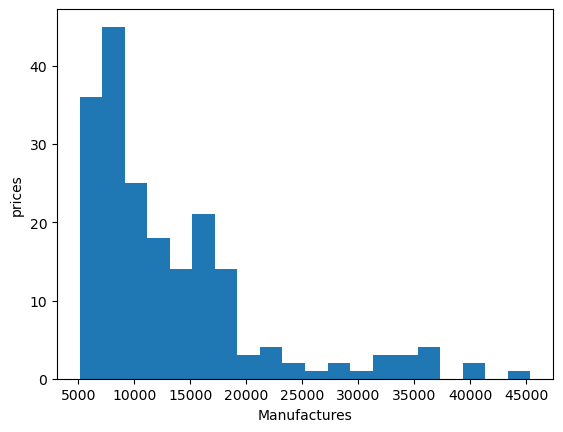

In [64]:
import matplotlib.pyplot as plt

plt.hist(df_clean["price"],bins=20)
plt.xlabel("Manufactures")
plt.ylabel("prices")
plt.plot()



### Question 39
Create a **bar chart** showing the average price for each body style.


[]

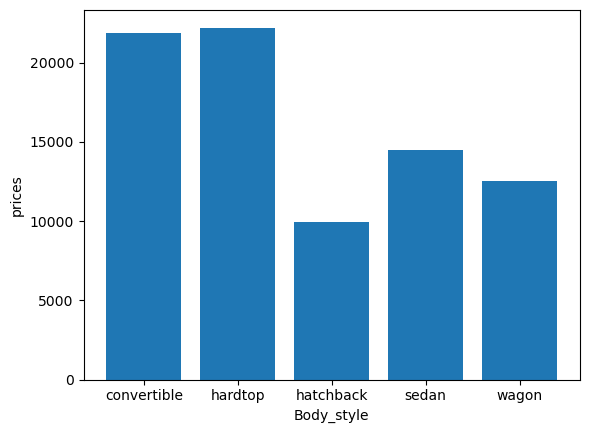

In [69]:
# plt.bar(df_clean["body_style"],df_clean["price"].mean())
# plt.xlabel("Body_style")
# plt.ylabel("prices")
# plt.plot()

x=df_clean.groupby("body_style")["price"].mean()

plt.bar(x.index,x.values)
plt.xlabel("Body_style")
plt.ylabel("prices")
plt.plot()

### Question 40
Save `df_clean` as **Automobile_Cleaned.csv** using `to_csv()` without saving the index.


In [66]:
df_clean.to_csv("Automobile_Cleaned.csv",index=False)

## End of Practice

Try to solve each question independently before checking any reference material.

The main goal is to become comfortable with cleaning and analyzing a dataset that contains numerical values, categories, and missing information before moving to predictive modeling.
